In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import numpy as np
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import time

PROJECT_DIR = "/content/drive/MyDrive/AgenticX_Handwritten_Character_Recognition"

DATA_DIR = os.path.join(PROJECT_DIR, "data")
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
PLOTS_DIR = os.path.join(PROJECT_DIR, "plots")
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
PREDICTIONS_DIR = os.path.join(PROJECT_DIR, "predictions")

print("Project paths restored.")
print("TensorFlow version:", tf.__version__)
print("Project folder exists:", os.path.exists(PROJECT_DIR))

Project paths restored.
TensorFlow version: 2.21.0
Project folder exists: True


In [3]:
# Load preprocessed test data from Google Drive
preprocessed_path = os.path.join(
    DATA_DIR, "mnist_preprocessed.npz"
)

data = np.load(preprocessed_path)

x_test_cnn = data["x_test_cnn"]
y_test = data["y_test"]

# Load the complete trained CNN v1 model
cnn_v1_model_path = os.path.join(
    MODEL_DIR, "cnn_v1.keras"
)

cnn_v1 = keras.models.load_model(cnn_v1_model_path)

print("Saved CNN v1 model loaded successfully!")
print("Test images:", x_test_cnn.shape)
print("Test labels:", y_test.shape)
print("Model parameters:", cnn_v1.count_params())

Saved CNN v1 model loaded successfully!
Test images: (10000, 28, 28, 1)
Test labels: (10000,)
Model parameters: 693962


In [4]:
# Evaluate on the separate 10,000-image test set
test_loss, test_accuracy = cnn_v1.evaluate(
    x_test_cnn,
    y_test,
    verbose=1
)

# Measure inference time
start_time = time.perf_counter()

y_pred_prob = cnn_v1.predict(
    x_test_cnn,
    batch_size=256,
    verbose=1
)

inference_time = time.perf_counter() - start_time

y_pred = np.argmax(y_pred_prob, axis=1)

print("\n===== CNN v1 TEST RESULTS =====")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")
print(f"Test loss: {test_loss:.4f}")
print(f"Total prediction time: {inference_time:.4f} seconds")
print(
    "Average inference time per image: "
    f"{inference_time / len(x_test_cnn) * 1000:.4f} ms"
)

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9808 - loss: 0.0723
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step

===== CNN v1 TEST RESULTS =====
Test accuracy: 98.08%
Test loss: 0.0723
Total prediction time: 1.0657 seconds
Average inference time per image: 0.1066 ms


In [5]:
# Save evaluation metrics
evaluation_path = os.path.join(
    RESULTS_DIR, "cnn_v1_test_metrics.npz"
)

np.savez(
    evaluation_path,
    test_accuracy=test_accuracy,
    test_loss=test_loss,
    inference_time_seconds=inference_time,
    average_inference_time_ms=(
        inference_time / len(x_test_cnn) * 1000
    )
)

# Save predictions for later error analysis
predictions_path = os.path.join(
    PREDICTIONS_DIR, "cnn_v1_test_predictions.npz"
)

np.savez_compressed(
    predictions_path,
    y_true=y_test,
    y_pred=y_pred,
    y_pred_prob=y_pred_prob
)

print("Evaluation metrics saved:", evaluation_path)
print("Test predictions saved:", predictions_path)

Evaluation metrics saved: /content/drive/MyDrive/AgenticX_Handwritten_Character_Recognition/results/cnn_v1_test_metrics.npz
Test predictions saved: /content/drive/MyDrive/AgenticX_Handwritten_Character_Recognition/predictions/cnn_v1_test_predictions.npz


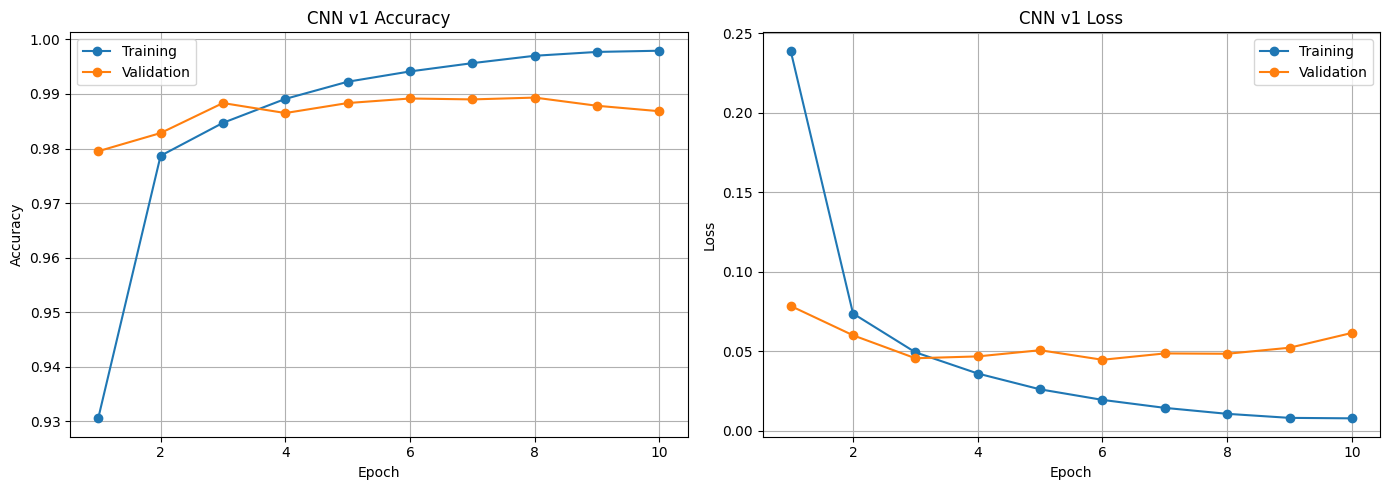

Training curves saved: /content/drive/MyDrive/AgenticX_Handwritten_Character_Recognition/plots/cnn_v1_training_curves.png


In [6]:
import matplotlib.pyplot as plt

history_path = os.path.join(
    RESULTS_DIR, "cnn_v1_history.npz"
)

history_data = np.load(history_path)

train_acc = history_data["accuracy"]
val_acc = history_data["val_accuracy"]
train_loss = history_data["loss"]
val_loss = history_data["val_loss"]

epochs = range(1, len(train_acc) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs, train_acc, marker="o", label="Training")
axes[0].plot(epochs, val_acc, marker="o", label="Validation")
axes[0].set_title("CNN v1 Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epochs, train_loss, marker="o", label="Training")
axes[1].plot(epochs, val_loss, marker="o", label="Validation")
axes[1].set_title("CNN v1 Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()

curve_path = os.path.join(
    PLOTS_DIR, "cnn_v1_training_curves.png"
)

plt.savefig(curve_path, dpi=150, bbox_inches="tight")
plt.show()

print("Training curves saved:", curve_path)

In [7]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)
import numpy as np
import os

predictions_path = os.path.join(
    PREDICTIONS_DIR,
    "cnn_v1_test_predictions.npz"
)

saved_predictions = np.load(predictions_path)

y_true = saved_predictions["y_true"]
y_pred = saved_predictions["y_pred"]

print("===== CNN v1 CLASSIFICATION REPORT =====")
print(
    classification_report(
        y_true,
        y_pred,
        digits=4
    )
)

===== CNN v1 CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

           0     0.9789    0.9949    0.9868       980
           1     0.9921    0.9921    0.9921      1135
           2     0.9883    0.9797    0.9839      1032
           3     0.9821    0.9792    0.9807      1010
           4     0.9848    0.9919    0.9883       982
           5     0.9954    0.9608    0.9778       892
           6     0.9843    0.9802    0.9822       958
           7     0.9826    0.9864    0.9845      1028
           8     0.9280    0.9918    0.9588       974
           9     0.9948    0.9485    0.9711      1009

    accuracy                         0.9808     10000
   macro avg     0.9811    0.9805    0.9806     10000
weighted avg     0.9813    0.9808    0.9808     10000



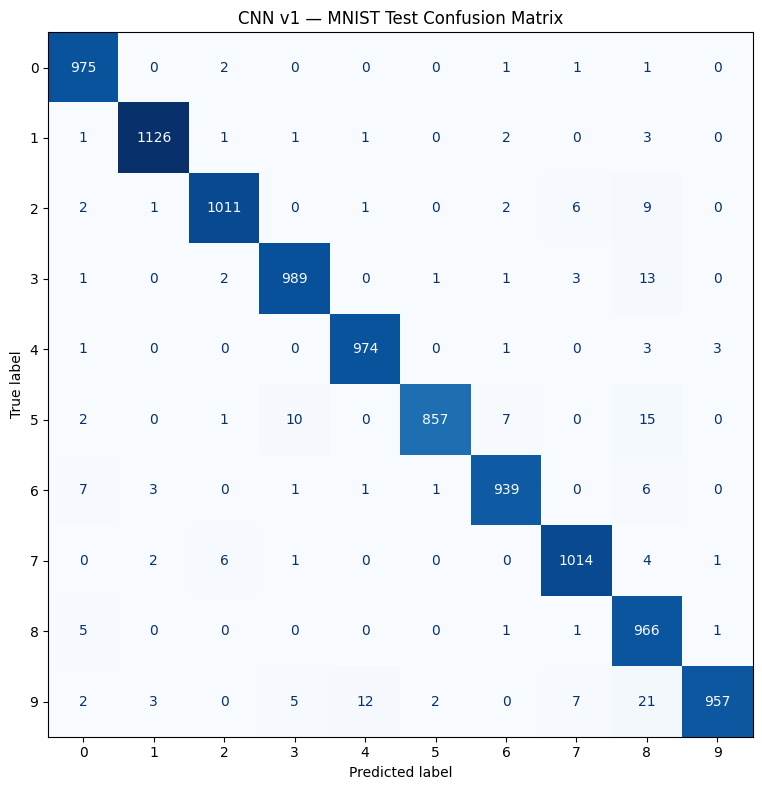

Confusion matrix saved: /content/drive/MyDrive/AgenticX_Handwritten_Character_Recognition/plots/cnn_v1_confusion_matrix.png


In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(10, 8))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("CNN v1 — MNIST Test Confusion Matrix")
plt.tight_layout()

cm_path = os.path.join(
    PLOTS_DIR,
    "cnn_v1_confusion_matrix.png"
)

plt.savefig(cm_path, dpi=150, bbox_inches="tight")
plt.show()

print("Confusion matrix saved:", cm_path)

In [10]:
from IPython.display import display as show_table
import pandas as pd
import os

error_csv_path = os.path.join(
    RESULTS_DIR,
    "cnn_v1_worst_20_errors.csv"
)

error_df = pd.read_csv(error_csv_path)

show_table(error_df.round(4))

,test_image_index,actual_digit,predicted_digit,wrong_prediction_confidence,true_digit_probability
0,5955,3,8,1.0000,0.0000
1,1393,5,3,0.9999,0.0000
2,9729,5,6,0.9999,0.0000
3,2896,8,0,0.9996,0.0001
4,9015,7,2,0.9994,0.0006
5,2654,6,1,0.9994,0.0003
6,1530,8,7,0.9993,0.0007
7,1678,2,0,0.9990,0.0008
8,445,6,0,0.9990,0.0010
9,2035,5,3,0.9990,0.0010


In [11]:
import os
import numpy as np
import pandas as pd

# Load saved Logistic Regression metrics
baseline_path = os.path.join(
    RESULTS_DIR, "baseline_metrics.npz"
)
baseline = np.load(baseline_path)

# Load saved CNN v1 test metrics
cnn_path = os.path.join(
    RESULTS_DIR, "cnn_v1_test_metrics.npz"
)
cnn = np.load(cnn_path)

# Build comparison table
baseline_accuracy = float(baseline["accuracy"])
cnn_accuracy = float(cnn["test_accuracy"])

comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Test Accuracy (%)": baseline_accuracy * 100,
        "Total Inference Time (s)": float(baseline["inference_time"]),
        "Average Inference Time (ms/image)": float(
            baseline["average_inference_time_ms"]
        )
    },
    {
        "Model": "CNN v1",
        "Test Accuracy (%)": cnn_accuracy * 100,
        "Total Inference Time (s)": float(
            cnn["inference_time_seconds"]
        ),
        "Average Inference Time (ms/image)": float(
            cnn["average_inference_time_ms"]
        )
    }
])

comparison_path = os.path.join(
    RESULTS_DIR, "model_comparison.csv"
)
comparison.to_csv(comparison_path, index=False)

print("===== MODEL COMPARISON =====")
print(comparison.round(4).to_string(index=False))
print(
    f"\nCNN accuracy improvement: "
    f"{(cnn_accuracy - baseline_accuracy) * 100:.2f} percentage points"
)
print("\nComparison saved to:", comparison_path)

===== MODEL COMPARISON =====
              Model  Test Accuracy (%)  Total Inference Time (s)  Average Inference Time (ms/image)
Logistic Regression              92.59                    0.1567                             0.0157
             CNN v1              98.08                    1.0657                             0.1066

CNN accuracy improvement: 5.49 percentage points

Comparison saved to: /content/drive/MyDrive/AgenticX_Handwritten_Character_Recognition/results/model_comparison.csv


In [15]:
import os
import numpy as np

data_path = os.path.join(DATA_DIR, "mnist_preprocessed.npz")
data = np.load(data_path)

print("Available keys:", data.files)

for key in data.files:
    print(key, "->", data[key].shape, data[key].dtype)


Available keys: ['x_train_cnn', 'x_test_cnn', 'x_train_flat', 'x_test_flat', 'y_train', 'y_test']
x_train_cnn -> (60000, 28, 28, 1) float32
x_test_cnn -> (10000, 28, 28, 1) float32
x_train_flat -> (60000, 784) float32
x_test_flat -> (10000, 784) float32
y_train -> (60000,) uint8
y_test -> (10000,) uint8


In [16]:

import os
import numpy as np
from tensorflow import keras
from tensorflow.keras import layers

# Load existing preprocessed dataset
data = np.load(
    os.path.join(DATA_DIR, "mnist_preprocessed.npz")
)

X_train = data["x_train_cnn"]
y_train = data["y_train"]

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)

# Build CNN v2
cnn_v2 = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Additional convolutional layer compared with CNN v1
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])

cnn_v2.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_v2.summary()


Training images: (60000, 28, 28, 1)
Training labels: (60000,)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:

checkpoint_callback = keras.callbacks.ModelCheckpoint(
    filepath=os.path.join(
        CHECKPOINT_DIR,
        "cnn_v2_epoch_{epoch:02d}.weights.h5"
    ),
    save_weights_only=True,
    save_freq="epoch",
    verbose=0
)

history_v2 = cnn_v2.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    callbacks=[checkpoint_callback],
    verbose=1
)

# Save the completed model
cnn_v2.save(os.path.join(MODEL_DIR, "cnn_v2.keras"))

# Save training history
np.savez(
    os.path.join(RESULTS_DIR, "cnn_v2_history.npz"),
    accuracy=history_v2.history["accuracy"],
    val_accuracy=history_v2.history["val_accuracy"],
    loss=history_v2.history["loss"],
    val_loss=history_v2.history["val_loss"]
)

print("CNN v2 model saved successfully.")
print("Training history saved successfully.")


Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 14s 20ms/step - accuracy: 0.9354 - loss: 0.2201 - val_accuracy: 0.9802 - val_loss: 0.0703
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9809 - loss: 0.0623 - val_accuracy: 0.9868 - val_loss: 0.0461
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9871 - loss: 0.0426 - val_accuracy: 0.9883 - val_loss: 0.0457
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9902 - loss: 0.0325 - val_accuracy: 0.9855 - val_loss: 0.0459
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9917 - loss: 0.0266 - val_accuracy: 0.9898 - val_loss: 0.0380
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9933 - loss: 0.0208 - val_accuracy: 0.9897 - val_loss: 0.0383
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9951 - loss: 0.0162 - val_accuracy: 0.9902 - val_loss: 0.0385
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9951 - loss: 0.0148 - val_accuracy: 

In [18]:

import os
import time
import numpy as np
from tensorflow import keras

# Load the saved model
cnn_v2 = keras.models.load_model(
    os.path.join(MODEL_DIR, "cnn_v2.keras")
)

# Load test images and labels
data = np.load(
    os.path.join(DATA_DIR, "mnist_preprocessed.npz")
)

X_test = data["x_test_cnn"]
y_test = data["y_test"]

# Evaluate model
test_loss, test_accuracy = cnn_v2.evaluate(
    X_test, y_test, verbose=1
)

# Measure prediction time
start_time = time.perf_counter()
y_pred_prob = cnn_v2.predict(X_test, verbose=0)
inference_time = time.perf_counter() - start_time

y_pred = np.argmax(y_pred_prob, axis=1)
average_inference_time_ms = (
    inference_time / len(X_test) * 1000
)

print(f"Test accuracy: {test_accuracy * 100:.2f}%")
print(f"Test loss: {test_loss:.4f}")
print(f"Total prediction time: {inference_time:.4f} seconds")
print(
    f"Average prediction time: "
    f"{average_inference_time_ms:.4f} ms/image"
)
print(f"Incorrect predictions: {np.sum(y_pred != y_test)}")

# Save metrics
np.savez(
    os.path.join(RESULTS_DIR, "cnn_v2_test_metrics.npz"),
    test_accuracy=test_accuracy,
    test_loss=test_loss,
    inference_time_seconds=inference_time,
    average_inference_time_ms=average_inference_time_ms
)

# Save predictions for later error analysis
np.savez(
    os.path.join(PREDICTIONS_DIR, "cnn_v2_test_predictions.npz"),
    y_true=y_test,
    y_pred=y_pred,
    y_pred_prob=y_pred_prob
)

print("CNN v2 test metrics and predictions saved.")


313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.9899 - loss: 0.0342
Test accuracy: 98.99%
Test loss: 0.0342
Total prediction time: 1.3114 seconds
Average prediction time: 0.1311 ms/image
Incorrect predictions: 101
CNN v2 test metrics and predictions saved.


===== CNN V2 CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

           0     0.9949    0.9857    0.9903       980
           1     0.9939    0.9974    0.9956      1135
           2     0.9971    0.9845    0.9907      1032
           3     0.9930    0.9891    0.9911      1010
           4     0.9869    0.9959    0.9914       982
           5     0.9768    0.9922    0.9844       892
           6     0.9927    0.9896    0.9911       958
           7     0.9790    0.9971    0.9880      1028
           8     0.9948    0.9877    0.9912       974
           9     0.9890    0.9792    0.9841      1009

    accuracy                         0.9899     10000
   macro avg     0.9898    0.9898    0.9898     10000
weighted avg     0.9900    0.9899    0.9899     10000



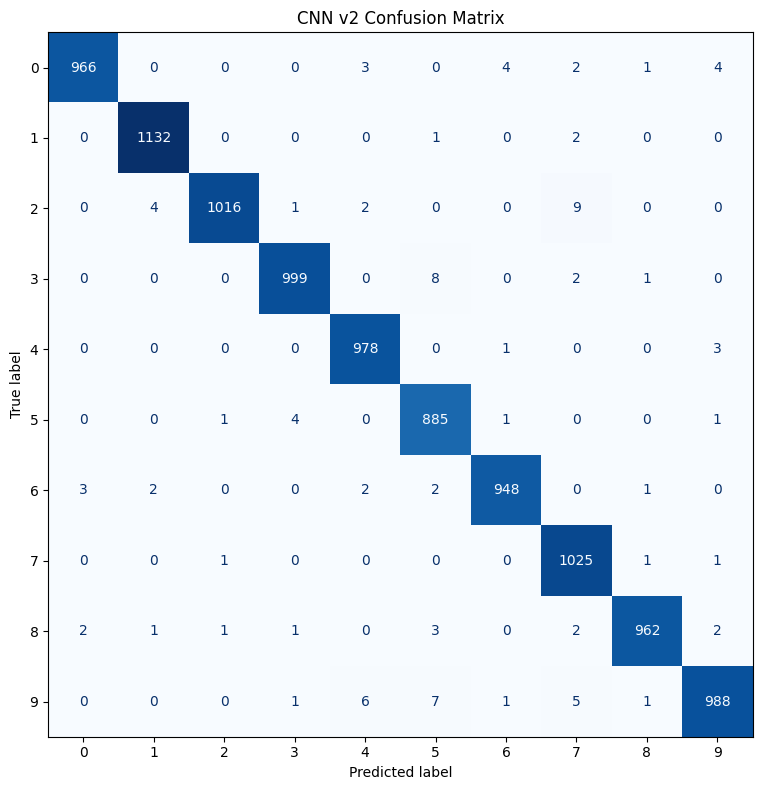

Confusion matrix saved to: /content/drive/MyDrive/AgenticX_Handwritten_Character_Recognition/plots/cnn_v2_confusion_matrix.png


In [19]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Load saved predictions
pred_data = np.load(
    os.path.join(
        PREDICTIONS_DIR,
        "cnn_v2_test_predictions.npz"
    )
)

y_true = pred_data["y_true"]
y_pred = pred_data["y_pred"]

# Classification report
report = classification_report(
    y_true,
    y_pred,
    digits=4,
    zero_division=0
)

print("===== CNN V2 CLASSIFICATION REPORT =====")
print(report)

# Save report
with open(
    os.path.join(RESULTS_DIR, "cnn_v2_classification_report.txt"),
    "w"
) as f:
    f.write(report)

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(9, 8))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
)
disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title("CNN v2 Confusion Matrix")
plt.tight_layout()

cm_path = os.path.join(PLOTS_DIR, "cnn_v2_confusion_matrix.png")
plt.savefig(cm_path, dpi=150, bbox_inches="tight")
plt.show()

print("Confusion matrix saved to:", cm_path)


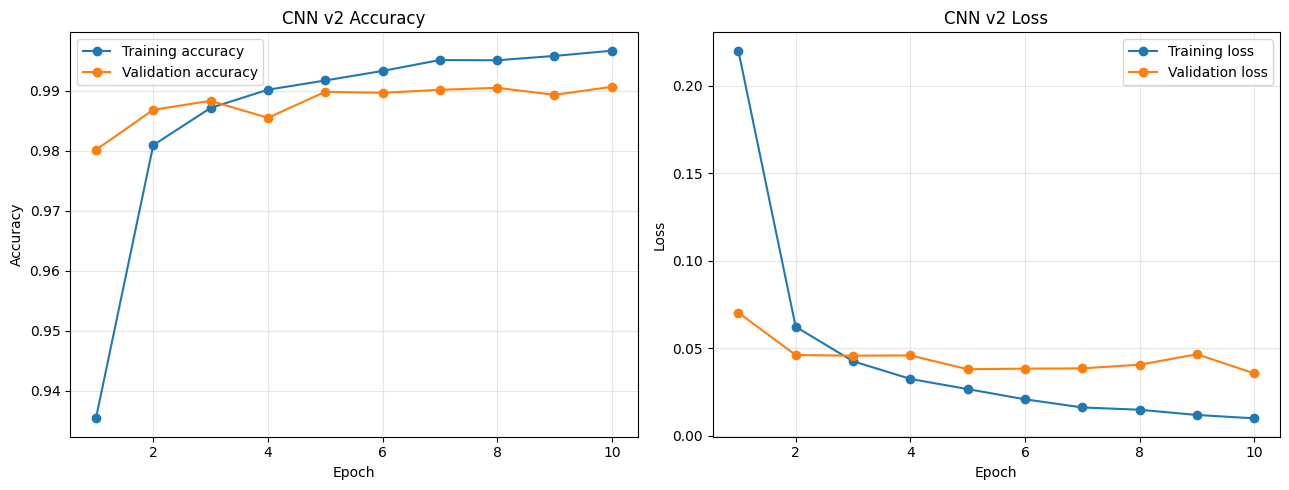

Training curves saved to: /content/drive/MyDrive/AgenticX_Handwritten_Character_Recognition/plots/cnn_v2_training_curves.png


In [20]:

history_data = np.load(
    os.path.join(RESULTS_DIR, "cnn_v2_history.npz")
)

epochs = np.arange(1, len(history_data["accuracy"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(epochs, history_data["accuracy"], marker="o",
             label="Training accuracy")
axes[0].plot(epochs, history_data["val_accuracy"], marker="o",
             label="Validation accuracy")
axes[0].set_title("CNN v2 Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs, history_data["loss"], marker="o",
             label="Training loss")
axes[1].plot(epochs, history_data["val_loss"], marker="o",
             label="Validation loss")
axes[1].set_title("CNN v2 Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()

curve_path = os.path.join(PLOTS_DIR, "cnn_v2_training_curves.png")
plt.savefig(curve_path, dpi=150, bbox_inches="tight")
plt.show()

print("Training curves saved to:", curve_path)


Total incorrect predictions: 101

20 most confidently incorrect predictions:
 test_image_index  actual_digit  predicted_digit  wrong_prediction_confidence  true_digit_probability
             3727             8                9                       0.9997                  0.0003
             4740             3                5                       0.9994                  0.0006
             2597             5                3                       0.9990                  0.0010
             2896             8                0                       0.9986                  0.0013
             3520             6                4                       0.9985                  0.0001
             1790             2                7                       0.9971                  0.0029
              947             8                9                       0.9970                  0.0029
             2654             6                1                       0.9970                  0.0024
     

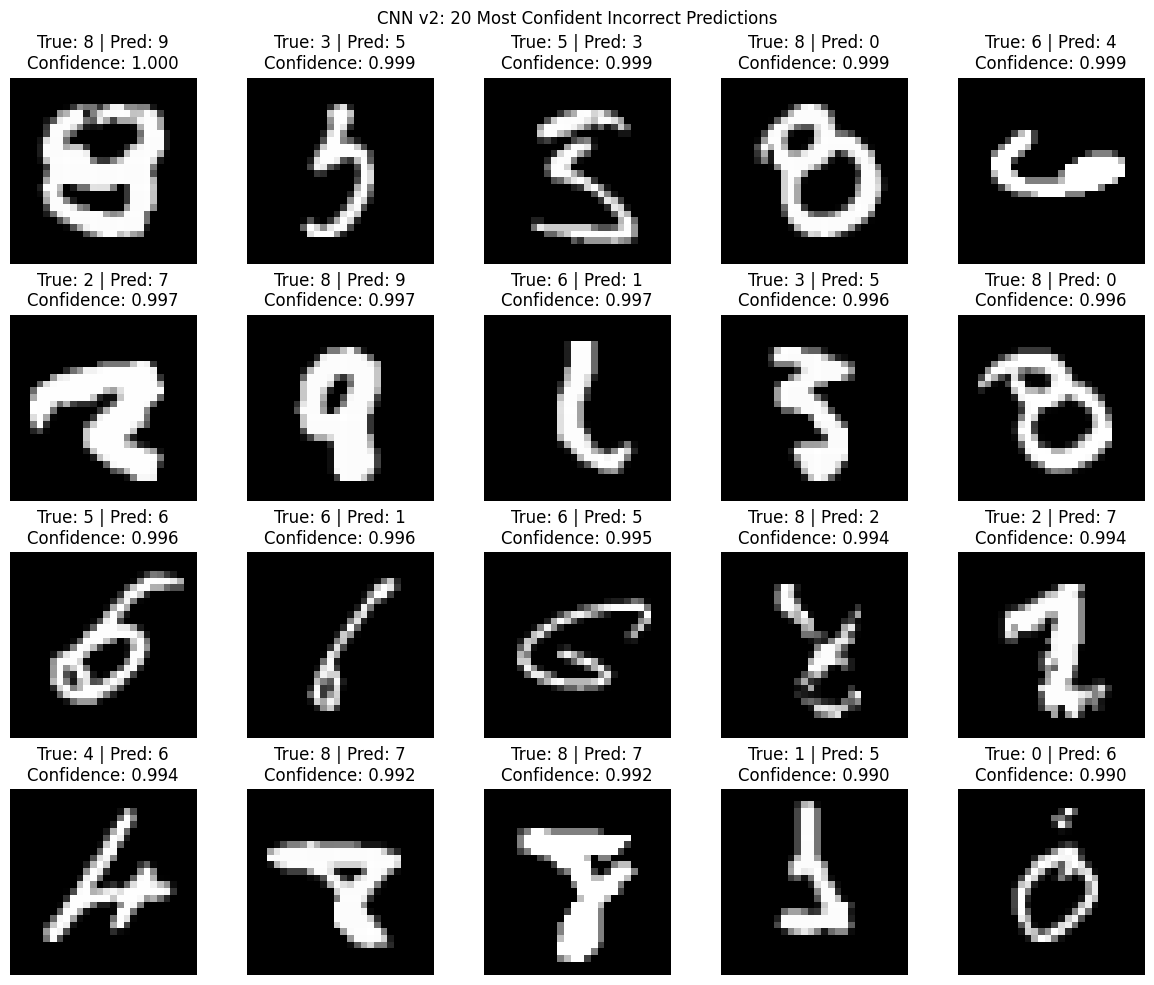


CSV saved to: /content/drive/MyDrive/AgenticX_Handwritten_Character_Recognition/results/cnn_v2_worst_20_errors.csv
Plot saved to: /content/drive/MyDrive/AgenticX_Handwritten_Character_Recognition/plots/cnn_v2_worst_20_predictions.png


In [21]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load saved test data and CNN v2 predictions
data = np.load(
    os.path.join(DATA_DIR, "mnist_preprocessed.npz")
)
pred_data = np.load(
    os.path.join(PREDICTIONS_DIR, "cnn_v2_test_predictions.npz")
)

X_test = data["x_test_cnn"]
y_true = pred_data["y_true"]
y_pred = pred_data["y_pred"]
y_prob = pred_data["y_pred_prob"]

# Find all incorrect predictions
wrong_indices = np.where(y_true != y_pred)[0]
wrong_confidence = np.max(y_prob[wrong_indices], axis=1)

# Select the 20 most confident incorrect predictions
order = np.argsort(wrong_confidence)[::-1][:20]
worst_indices = wrong_indices[order]

error_df = pd.DataFrame({
    "test_image_index": worst_indices,
    "actual_digit": y_true[worst_indices],
    "predicted_digit": y_pred[worst_indices],
    "wrong_prediction_confidence": np.max(
        y_prob[worst_indices], axis=1
    ),
    "true_digit_probability": y_prob[
        worst_indices, y_true[worst_indices]
    ]
})

csv_path = os.path.join(
    RESULTS_DIR, "cnn_v2_worst_20_errors.csv"
)
error_df.to_csv(csv_path, index=False)

print("Total incorrect predictions:", len(wrong_indices))
print("\n20 most confidently incorrect predictions:")
print(error_df.round(4).to_string(index=False))

# Plot the 20 incorrectly classified images
fig, axes = plt.subplots(4, 5, figsize=(12, 10))

for ax, idx in zip(axes.flat, worst_indices):
    ax.imshow(X_test[idx].squeeze(), cmap="gray")
    ax.set_title(
        f"True: {y_true[idx]} | Pred: {y_pred[idx]}\n"
        f"Confidence: {np.max(y_prob[idx]):.3f}"
    )
    ax.axis("off")

plt.suptitle("CNN v2: 20 Most Confident Incorrect Predictions")
plt.tight_layout()

plot_path = os.path.join(
    PLOTS_DIR, "cnn_v2_worst_20_predictions.png"
)
plt.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()

print("\nCSV saved to:", csv_path)
print("Plot saved to:", plot_path)


In [22]:

import os
import numpy as np
import pandas as pd

# Load saved metrics
baseline = np.load(
    os.path.join(RESULTS_DIR, "baseline_metrics.npz")
)
cnn1 = np.load(
    os.path.join(RESULTS_DIR, "cnn_v1_test_metrics.npz")
)
cnn2 = np.load(
    os.path.join(RESULTS_DIR, "cnn_v2_test_metrics.npz")
)

comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Test Accuracy (%)": float(baseline["accuracy"]) * 100,
        "Incorrect Predictions": round(
            (1 - float(baseline["accuracy"])) * 10000
        ),
        "Avg Inference (ms/image)": float(
            baseline["average_inference_time_ms"]
        )
    },
    {
        "Model": "CNN v1",
        "Test Accuracy (%)": float(cnn1["test_accuracy"]) * 100,
        "Incorrect Predictions": round(
            (1 - float(cnn1["test_accuracy"])) * 10000
        ),
        "Avg Inference (ms/image)": float(
            cnn1["average_inference_time_ms"]
        )
    },
    {
        "Model": "CNN v2",
        "Test Accuracy (%)": float(cnn2["test_accuracy"]) * 100,
        "Incorrect Predictions": round(
            (1 - float(cnn2["test_accuracy"])) * 10000
        ),
        "Avg Inference (ms/image)": float(
            cnn2["average_inference_time_ms"]
        )
    }
])

comparison_path = os.path.join(
    RESULTS_DIR, "final_model_comparison.csv"
)
comparison.to_csv(comparison_path, index=False)

print("===== FINAL MODEL COMPARISON =====")
print(comparison.round(4).to_string(index=False))

print("\nCNN v2 vs CNN v1 accuracy improvement:",
      f"{(float(cnn2['test_accuracy']) - float(cnn1['test_accuracy'])) * 100:.2f}",
      "percentage points")

print("\nSaved to:", comparison_path)


===== FINAL MODEL COMPARISON =====
              Model  Test Accuracy (%)  Incorrect Predictions  Avg Inference (ms/image)
Logistic Regression              92.59                    741                    0.0157
             CNN v1              98.08                    192                    0.1066
             CNN v2              98.99                    101                    0.1311

CNN v2 vs CNN v1 accuracy improvement: 0.91 percentage points

Saved to: /content/drive/MyDrive/AgenticX_Handwritten_Character_Recognition/results/final_model_comparison.csv


In [23]:
import os

folders_to_check = {
    "Models": MODEL_DIR,
    "Results": RESULTS_DIR,
    "Plots": PLOTS_DIR,
    "Predictions": PREDICTIONS_DIR,
    "Checkpoints": CHECKPOINT_DIR
}

for folder_name, folder_path in folders_to_check.items():
    print(f"\n===== {folder_name} =====")

    if not os.path.isdir(folder_path):
        print("Folder not found:", folder_path)
        continue

    files = sorted(os.listdir(folder_path))

    for filename in files:
        full_path = os.path.join(folder_path, filename)

        if os.path.isfile(full_path):
            size_mb = os.path.getsize(full_path) / (1024 * 1024)
            print(f"{filename} ({size_mb:.2f} MB)")
        elif os.path.isdir(full_path):
            print(f"{filename}/")



===== Models =====
cnn_v1.keras (7.97 MB)
cnn_v2.keras (2.61 MB)
logistic_regression_baseline.joblib (0.06 MB)

===== Results =====
baseline_metrics.npz (0.00 MB)
cnn_v1_history.npz (0.00 MB)
cnn_v1_test_metrics.npz (0.00 MB)
cnn_v1_worst_20_errors.csv (0.00 MB)
cnn_v2_classification_report.txt (0.00 MB)
cnn_v2_history.npz (0.00 MB)
cnn_v2_test_metrics.npz (0.00 MB)
cnn_v2_worst_20_errors.csv (0.00 MB)
final_model_comparison.csv (0.00 MB)
model_comparison.csv (0.00 MB)

===== Plots =====
cnn_v1_confusion_matrix.png (0.06 MB)
cnn_v1_training_curves.png (0.09 MB)
cnn_v1_worst_20_predictions.png (0.12 MB)
cnn_v2_confusion_matrix.png (0.06 MB)
cnn_v2_training_curves.png (0.08 MB)
cnn_v2_worst_20_predictions.png (0.09 MB)
logistic_regression_confusion_matrix.png (0.08 MB)

===== Predictions =====
cnn_v1_test_predictions.npz (0.37 MB)
cnn_v2_test_predictions.npz (0.47 MB)

===== Checkpoints =====
cnn_v1_epoch_01.weights.h5 (7.97 MB)
cnn_v1_epoch_02.weights.h5 (7.97 MB)
cnn_v1_epoch_03.weigh

In [24]:
import os

README_PATH = os.path.join(PROJECT_DIR, "README.md")
REQUIREMENTS_PATH = os.path.join(PROJECT_DIR, "requirements.txt")

readme_content = r"""# Handwritten Digit Recognition using CNN

A machine learning project developed as part of the AgenticX Machine Learning Internship. The project classifies handwritten digits (0–9) from the MNIST dataset and compares a traditional machine learning baseline with two Convolutional Neural Network (CNN) architectures.

## Project Overview

The objective is to build, evaluate, and compare models for handwritten digit recognition using a consistent test dataset.

### Models
1. **Logistic Regression:** Non-neural baseline using flattened 28×28 images.
2. **CNN v1:** A simple CNN with one convolutional layer.
3. **CNN v2:** An improved CNN with two convolutional layers.

## Dataset

- Dataset: MNIST handwritten digits
- Training images: 60,000
- Test images: 10,000
- Image dimensions: 28 × 28 pixels
- Number of classes: 10 (digits 0–9)
- Preprocessing: Images normalized to the range [0, 1].
- CNN input shape: 28 × 28 × 1

## Model Architectures

### Logistic Regression
Images are flattened into 784 features and classified using scikit-learn Logistic Regression.

### CNN v1
- Conv2D: 32 filters, 3 × 3, ReLU
- MaxPooling2D: 2 × 2
- Flatten
- Dense: 128 units, ReLU
- Dense: 10 units, Softmax

### CNN v2
- Conv2D: 32 filters, 3 × 3, ReLU
- MaxPooling2D: 2 × 2
- Conv2D: 64 filters, 3 × 3, ReLU
- MaxPooling2D: 2 × 2
- Flatten
- Dense: 128 units, ReLU
- Dense: 10 units, Softmax

Both CNNs use the Adam optimizer and sparse categorical cross-entropy loss. Training used a batch size of 128, 10 epochs, and a 10% validation split.

## Results

All three models were evaluated on the same 10,000 MNIST test images.

| Model | Test Accuracy | Incorrect Predictions |
|---|---:|---:|
| Logistic Regression | 92.59% | 741 |
| CNN v1 | 98.08% | 192 |
| CNN v2 | **98.99%** | **101** |

CNN v2 improved test accuracy by 0.91 percentage points over CNN v1 and reduced the number of errors from 192 to 101.

### Inference Timing

| Model | Average Measured Inference Time |
|---|---:|
| Logistic Regression | 0.0157 ms/image |
| CNN v1 | 0.1066 ms/image |
| CNN v2 | 0.1311 ms/image |

These are measurements from the project runtime, not a hardware-independent benchmark. Runtime and framework overhead can affect comparisons.

## Evaluation and Error Analysis

Evaluation includes:
- Test accuracy and loss
- Per-class precision, recall, and F1-score
- Confusion matrices
- Training and validation accuracy/loss curves
- Analysis of the 20 most confidently incorrect predictions

### CNN v2 Training Curves
![CNN v2 Training Curves](plots/cnn_v2_training_curves.png)

### CNN v2 Confusion Matrix
![CNN v2 Confusion Matrix](plots/cnn_v2_confusion_matrix.png)

### CNN v2 Error Analysis
![CNN v2 Worst 20 Predictions](plots/cnn_v2_worst_20_predictions.png)

The CNN v2 classification report shows a weighted F1-score of approximately 99.0%. The most confidently incorrect predictions also demonstrate that high prediction confidence does not guarantee correctness.

## Project Structure

```text
AgenticX_Handwritten_Character_Recognition/
├── data/
│   ├── mnist_dataset.npz
│   └── mnist_preprocessed.npz
├── models/
│   ├── logistic_regression_baseline.joblib
│   ├── cnn_v1.keras
│   └── cnn_v2.keras
├── checkpoints/
├── results/
│   ├── baseline_metrics.npz
│   ├── cnn_v1_test_metrics.npz
│   ├── cnn_v2_test_metrics.npz
│   ├── cnn_v2_classification_report.txt
│   └── final_model_comparison.csv
├── plots/
├── predictions/
├── requirements.txt
└── README.md
```

Generated datasets, model files, checkpoints, and prediction arrays are stored locally or in Google Drive and do not all need to be committed to GitHub.

## Installation

Use Python 3.11 or another Python version compatible with the installed TensorFlow release.

```bash
pip install -r requirements.txt
```

## Reproducing the Project

1. Obtain the MNIST dataset through TensorFlow/Keras.
2. Normalize the images and prepare CNN and flattened input formats.
3. Train the Logistic Regression baseline.
4. Train CNN v1 and save its training history and model.
5. Train CNN v2 using the additional convolutional layer.
6. Evaluate each model on the same held-out test set.
7. Generate the classification reports, confusion matrices, and error-analysis plots.

The saved models and results in this repository are artifacts from the completed experiment. Include the actual Colab notebook or training scripts in the repository if you want others to reproduce the full workflow directly.

## Technologies Used

- Python
- TensorFlow / Keras
- scikit-learn
- NumPy
- pandas
- Matplotlib
- Google Colab
- Google Drive

## Future Improvements

- Test data augmentation to improve robustness.
- Experiment with dropout or batch normalization.
- Compare inference latency under a controlled environment.
- Build a small interface for predicting digits from user-drawn images.
- Evaluate performance on handwritten samples outside MNIST.

## Acknowledgements

Developed as part of the AgenticX Machine Learning Internship.

Dataset: MNIST handwritten digits.
"""

requirements_content = """tensorflow==2.20.0
scikit-learn
numpy
pandas
matplotlib
joblib
"""

with open(README_PATH, "w", encoding="utf-8") as f:
    f.write(readme_content)

with open(REQUIREMENTS_PATH, "w", encoding="utf-8") as f:
    f.write(requirements_content)

print("README created:", README_PATH)
print("Requirements created:", REQUIREMENTS_PATH)
print("\nREADME size:", os.path.getsize(README_PATH), "bytes")
print("Requirements size:", os.path.getsize(REQUIREMENTS_PATH), "bytes")


README created: /content/drive/MyDrive/AgenticX_Handwritten_Character_Recognition/README.md
Requirements created: /content/drive/MyDrive/AgenticX_Handwritten_Character_Recognition/requirements.txt

README size: 5161 bytes
Requirements size: 63 bytes


In [25]:
for path in [README_PATH, REQUIREMENTS_PATH]:
    print("\n" + "=" * 60)
    print(os.path.basename(path))
    print("=" * 60)

    with open(path, "r", encoding="utf-8") as f:
        print(f.read()[:1200])



README.md
# Handwritten Digit Recognition using CNN

A machine learning project developed as part of the AgenticX Machine Learning Internship. The project classifies handwritten digits (0–9) from the MNIST dataset and compares a traditional machine learning baseline with two Convolutional Neural Network (CNN) architectures.

## Project Overview

The objective is to build, evaluate, and compare models for handwritten digit recognition using a consistent test dataset.

### Models
1. **Logistic Regression:** Non-neural baseline using flattened 28×28 images.
2. **CNN v1:** A simple CNN with one convolutional layer.
3. **CNN v2:** An improved CNN with two convolutional layers.

## Dataset

- Dataset: MNIST handwritten digits
- Training images: 60,000
- Test images: 10,000
- Image dimensions: 28 × 28 pixels
- Number of classes: 10 (digits 0–9)
- Preprocessing: Images normalized to the range [0, 1].
- CNN input shape: 28 × 28 × 1

## Model Architectures

### Logistic Regression
Images are fl